# SECOM — Isolation Forest vs Linear SVM



### Models

- Isolation Forest (normal-only anomaly detector)

- Linear SVM (class-weighted)



### Methodology kept from the exact earlier SECOM setup

- Official UCI SECOM download

- 80/20 stratified train/test split

- Completely untouched test set

- Constant-feature removal

- >50% missingness filtering

- Mann–Whitney U statistical screening

- Benjamini–Hochberg FDR

- Effect-size filtering

- Spearman correlation pruning

- Median imputation + missingness indicators

- 5-fold stratified out-of-fold evaluation

- OOF threshold selection using training data only

- Final test evaluation exactly once

- Balanced Accuracy, ROC-AUC, PR-AUC, Recall, Precision, F1

- Candidate process-signal analysis



### Important modeling note

Isolation Forest is fitted on **Pass observations only** inside each training fold, so its prediction is a genuine normal-profile anomaly score. Because the earlier statistical selector uses the pass/fail labels, this is a **label-informed / semi-supervised anomaly-detection benchmark**, not a purely unsupervised one. The test labels are used only for evaluation and threshold selection is performed from training OOF scores.


In [1]:
# Minimal installation for this notebook

%pip -q install -U scikit-learn scipy pandas matplotlib seaborn imbalanced-learn


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 2.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 21.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 22.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 52.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 30.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.


In [2]:
# 2. Imports



import io

import zipfile

import urllib.request

import warnings

import random



import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns



from scipy.stats import mannwhitneyu



from sklearn.base import BaseEstimator, TransformerMixin

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import RobustScaler

from sklearn.svm import LinearSVC

from sklearn.ensemble import IsolationForest

from sklearn.metrics import (

    balanced_accuracy_score,

    roc_auc_score,

    average_precision_score,

    precision_score,

    recall_score,

    f1_score,

    confusion_matrix,

    classification_report,

)



from imblearn.pipeline import Pipeline



warnings.filterwarnings("ignore")



SEED = 42

np.random.seed(SEED)

random.seed(SEED)



print("Imports successful.")


Imports successful.


In [3]:
# 3. Optional environment check

print("NumPy :", np.__version__)
print("Pandas:", pd.__version__)

from scipy.stats import mannwhitneyu
print("SciPy import: OK")


NumPy : 2.1.3
Pandas: 3.0.6
SciPy import: OK


In [4]:
# 4. Load official UCI SECOM data

URL = "https://archive.ics.uci.edu/static/public/179/secom.zip"

def load_secom():
    with urllib.request.urlopen(URL, timeout=60) as response:
        raw = response.read()

    with zipfile.ZipFile(io.BytesIO(raw)) as z:
        names = z.namelist()

        def locate(filename):
            matches = [n for n in names if n.lower().endswith(filename.lower())]
            if not matches:
                raise FileNotFoundError(
                    f"{filename} not found in official UCI archive."
                )
            return matches[0]

        data_file = locate("secom.data")
        label_file = locate("secom_labels.data")

        with z.open(data_file) as f:
            X = pd.read_csv(
                f,
                sep=r"\s+",
                header=None,
                engine="python"
            )

        # The label file contains: label, date, time
        with z.open(label_file) as f:
            labels = pd.read_csv(
                f,
                sep=r"\s+",
                header=None,
                names=["label", "date", "time"],
                engine="python"
            )

    if X.shape[0] != labels.shape[0]:
        raise ValueError(
            f"Feature/label row mismatch: {X.shape[0]} vs {labels.shape[0]}"
        )

    X.columns = [f"Sensor_{i+1}" for i in range(X.shape[1])]

    # UCI: -1 = pass, +1 = fail
    y = (labels["label"].astype(int) == 1).astype(int)

    timestamps = (
        labels["date"].astype(str).str.strip('"')
        + " "
        + labels["time"].astype(str).str.strip('"')
    )

    return X, y, timestamps


X, y, timestamps = load_secom()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nClass distribution:")
print(y.value_counts().sort_index())
print(f"\nFailure rate: {y.mean():.2%}")

# Hard safety checks
assert X.shape == (1567, 590), f"Unexpected X shape: {X.shape}"
assert len(y) == 1567, f"Unexpected y length: {len(y)}"
assert int(y.sum()) == 104, f"Expected 104 failures, got {int(y.sum())}"

print("\n✅ UCI SECOM loaded correctly.")


X shape: (1567, 590)
y shape: (1567,)

Class distribution:
label
0    1463
1     104
Name: count, dtype: int64

Failure rate: 6.64%

✅ UCI SECOM loaded correctly.


Number of features: 590
Constant features: 116
Features >50% missing: 28
Total missing cells: 41951


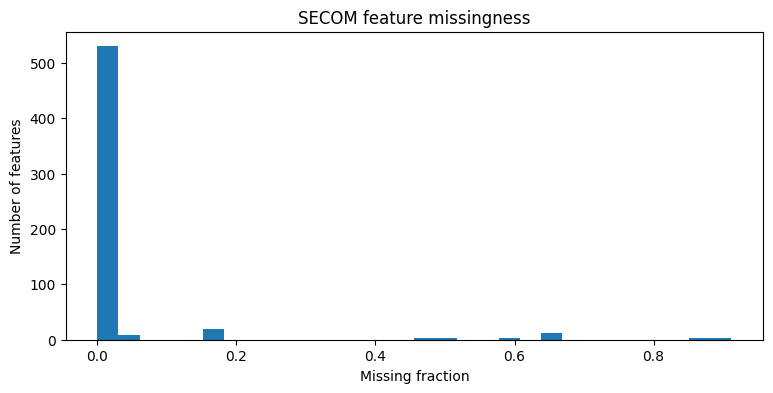

In [5]:
# 5. Data quality

missing_fraction = X.isna().mean()
constant_features = X.columns[X.nunique(dropna=True) <= 1].tolist()

print("Number of features:", X.shape[1])
print("Constant features:", len(constant_features))
print("Features >50% missing:", int((missing_fraction > 0.50).sum()))
print("Total missing cells:", int(X.isna().sum().sum()))

plt.figure(figsize=(9, 4))
plt.hist(missing_fraction, bins=30)
plt.xlabel("Missing fraction")
plt.ylabel("Number of features")
plt.title("SECOM feature missingness")
plt.show()


In [6]:
# 6. Untouched stratified test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)
print("Train failures:", int(y_train.sum()))
print("Test failures :", int(y_test.sum()))
print(f"Train failure rate: {y_train.mean():.2%}")
print(f"Test failure rate : {y_test.mean():.2%}")


Train shape: (1253, 590)
Test shape : (314, 590)
Train failures: 83
Test failures : 21
Train failure rate: 6.62%
Test failure rate : 6.69%


## 7. Leakage-free statistical feature selector

The selector is fitted separately in each CV training fold.

Within the fold it performs:
1. constant-feature removal
2. missingness filtering
3. temporary median imputation for statistical testing
4. Mann–Whitney U test
5. Benjamini–Hochberg FDR correction
6. robust median-difference effect size
7. rank-based AUC
8. feature ranking
9. Spearman redundancy pruning

The selected features are then passed to the downstream model.


In [7]:
class StatisticalFeatureSelector(BaseEstimator, TransformerMixin):
    def __init__(
        self,
        missing_threshold=0.50,
        fdr_alpha=0.05,
        min_effect=0.15,
        max_features=80,
        corr_threshold=0.90,
        min_features=10
    ):
        self.missing_threshold = missing_threshold
        self.fdr_alpha = fdr_alpha
        self.min_effect = min_effect
        self.max_features = max_features
        self.corr_threshold = corr_threshold
        self.min_features = min_features

    @staticmethod
    def bh_adjust(p):
        p = np.asarray(p, dtype=float)
        n = len(p)

        order = np.argsort(p)
        ranked = p[order]

        q = ranked * n / np.arange(1, n + 1)
        q = np.minimum.accumulate(q[::-1])[::-1]
        q = np.clip(q, 0, 1)

        out = np.empty(n)
        out[order] = q
        return out

    @staticmethod
    def rank_auc(a, b):
        n0, n1 = len(a), len(b)

        if n0 == 0 or n1 == 0:
            return 0.5

        values = np.concatenate([a, b])
        ranks = pd.Series(values).rank(method="average").to_numpy()

        # Positive-class rank sum -> Mann-Whitney U
        u = ranks[n0:].sum() - n1 * (n1 + 1) / 2
        auc = u / (n0 * n1)

        # Symmetric with respect to class direction
        return float(max(auc, 1 - auc))

    def fit(self, X, y):
        X = pd.DataFrame(X).copy()
        y = pd.Series(np.asarray(y)).reset_index(drop=True)
        X.reset_index(drop=True, inplace=True)

        self.feature_names_in_ = np.asarray(X.columns, dtype=object)

        # 1. Remove constant features using only this training fold.
        nonconstant = X.nunique(dropna=True) > 1
        candidates = X.columns[nonconstant].tolist()

        # 2. Missingness filter using only this training fold.
        candidates = [
            c for c in candidates
            if X[c].isna().mean() <= self.missing_threshold
        ]

        if not candidates:
            raise ValueError("No features survived quality filtering.")

        # 3. Temporary imputation for tests only.
        Xi = X[candidates].replace([np.inf, -np.inf], np.nan)
        Xi = Xi.fillna(Xi.median()).fillna(0)

        neg = y.to_numpy() == 0
        pos = y.to_numpy() == 1

        rows = []

        for feature in candidates:
            a = Xi.loc[neg, feature].to_numpy()
            b = Xi.loc[pos, feature].to_numpy()

            try:
                _, p_value = mannwhitneyu(
                    a, b,
                    alternative="two-sided"
                )
                auc = self.rank_auc(a, b)
            except Exception:
                p_value = 1.0
                auc = 0.5

            scale = np.nanstd(
                Xi[feature].to_numpy(),
                ddof=1
            )

            if not np.isfinite(scale) or scale <= 1e-12:
                effect = 0.0
            else:
                effect = (
                    abs(np.nanmedian(b) - np.nanmedian(a))
                    / scale
                )

            rows.append(
                (feature, p_value, effect, auc)
            )

        stats = pd.DataFrame(
            rows,
            columns=["feature", "p_value", "effect", "auc"]
        )

        stats["q_value"] = self.bh_adjust(stats["p_value"])
        stats["auc_distance"] = (stats["auc"] - 0.5).abs()

        # Primary statistical gate.
        selected = stats[
            (stats["q_value"] <= self.fdr_alpha) &
            (stats["effect"] >= self.min_effect)
        ].copy()

        # Robust fallback if the statistical gate is too strict.
        if len(selected) < self.min_features:
            selected = stats.sort_values(
                ["q_value", "auc_distance", "effect"],
                ascending=[True, False, False]
            ).head(
                min(self.max_features, len(stats))
            )

        selected = selected.sort_values(
            ["q_value", "auc_distance", "effect"],
            ascending=[True, False, False]
        ).head(self.max_features)

        names = selected["feature"].tolist()

        # Spearman redundancy pruning.
        if len(names) > 1:
            corr = Xi[names].corr(method="spearman").abs()

            kept = []

            for feature in names:
                if all(
                    corr.loc[feature, previous] < self.corr_threshold
                    for previous in kept
                ):
                    kept.append(feature)

            names = kept

        if not names:
            names = [
                stats.sort_values("q_value").iloc[0]["feature"]
            ]

        self.selected_features_ = names
        self.statistics_ = (
            stats.sort_values("q_value")
            .reset_index(drop=True)
        )

        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()

        missing = [
            c for c in self.selected_features_
            if c not in X.columns
        ]

        if missing:
            raise ValueError(
                f"Missing selected features: {missing[:5]}"
            )

        return X[self.selected_features_].copy()

    def get_feature_names_out(self, input_features=None):
        return np.asarray(
            self.selected_features_,
            dtype=object
        )


## 8. Define the two models



Both branches keep the same statistical-feature pipeline from the earlier exact setup.



The final estimator differs:



- **Linear SVM:** a linear large-margin classifier, appropriate to test the hypothesis that much of the SECOM signal is approximately linear in the selected feature space.

- **Isolation Forest:** trained only on Pass observations in each training fold and evaluated as an anomaly detector. Its `decision_function` is inverted so that larger scores mean "more failure-like".


In [8]:
def new_selector():

    return StatisticalFeatureSelector(

        missing_threshold=0.50,

        fdr_alpha=0.05,

        min_effect=0.15,

        max_features=80,

        corr_threshold=0.90,

        min_features=10,

    )





class NormalOnlyIsolationForest(BaseEstimator):

    """Isolation Forest trained only on y=0 (Pass) training observations."""



    def __init__(

        self,

        n_estimators=500,

        max_samples="auto",

        contamination="auto",

        max_features=1.0,

        random_state=SEED,

    ):

        self.n_estimators = n_estimators

        self.max_samples = max_samples

        self.contamination = contamination

        self.max_features = max_features

        self.random_state = random_state



    def fit(self, X, y):

        X = np.asarray(X)

        y = np.asarray(y)



        normal_mask = (y == 0)

        if normal_mask.sum() < 20:

            raise ValueError("Too few normal/pass observations for Isolation Forest.")



        self.model_ = IsolationForest(

            n_estimators=self.n_estimators,

            max_samples=self.max_samples,

            contamination=self.contamination,

            max_features=self.max_features,

            random_state=self.random_state,

            n_jobs=-1,

        )

        self.model_.fit(X[normal_mask])

        return self



    def decision_function(self, X):

        # sklearn IsolationForest: higher = more normal.

        # Invert it so higher = more failure/anomaly-like.

        return -self.model_.decision_function(np.asarray(X))



    def predict(self, X):

        # Convenience only; the notebook uses thresholded anomaly scores.

        return (self.decision_function(X) >= 0).astype(int)



    @property

    def feature_importances_(self):

        return self.model_.feature_importances_





linear_svm_pipeline = Pipeline([

    ("selector", new_selector()),

    ("imputer", SimpleImputer(

        strategy="median",

        add_indicator=True

    )),

    ("scale", RobustScaler()),

    ("model", LinearSVC(

        C=1.0,

        class_weight="balanced",

        random_state=SEED,

        max_iter=10000,

    ))

])



isolation_forest_pipeline = Pipeline([

    ("selector", new_selector()),

    ("imputer", SimpleImputer(

        strategy="median",

        add_indicator=True

    )),

    ("model", NormalOnlyIsolationForest(

        n_estimators=500,

        max_samples="auto",

        contamination="auto",

        max_features=1.0,

        random_state=SEED,

    ))

])



models = {

    "Linear SVM": linear_svm_pipeline,

    "Isolation Forest": isolation_forest_pipeline,

}



print("Models ready:")

for name in models:

    print(" -", name)


Models ready:
 - Linear SVM
 - Isolation Forest


In [10]:
import copy


cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

oof_scores = {}
cv_rows = []


def get_scores(model, X_data, y_data=None, fit=False):
    """Return a failure-oriented score: larger means more failure-like."""
    if fit:
        model.fit(X_data, y_data)
    return np.asarray(model.decision_function(X_data))


def evaluate_scores(y_true, score, threshold=0.0, name="Model"):
    prediction = (score >= threshold).astype(int)

    return {
        "model": name,
        "threshold": threshold,
        "balanced_accuracy": balanced_accuracy_score(y_true, prediction),
        "roc_auc": roc_auc_score(y_true, score),
        "pr_auc": average_precision_score(y_true, score),
        "recall": recall_score(y_true, prediction, zero_division=0),
        "precision": precision_score(y_true, prediction, zero_division=0),
        "f1": f1_score(y_true, prediction, zero_division=0),
    }


for name, model in models.items():
    print("Running:", name)

    if name == "Isolation Forest":
        # Handle Isolation Forest separately as it's an anomaly detector
        # and cross_val_predict expects `classes_` for classifiers.
        current_oof_scores = np.zeros(X_train.shape[0])
        for fold, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train)):
            X_train_fold, X_val_fold = X_train.iloc[train_idx], X_train.iloc[val_idx]
            y_train_fold, y_val_fold = y_train.iloc[train_idx], y_train.iloc[val_idx]

            # Create a fresh model copy for each fold to prevent data leakage across folds
            # This is equivalent to how cross_val_predict handles estimators.
            fold_model = copy.deepcopy(model)
            fold_model.fit(X_train_fold, y_train_fold)
            current_oof_scores[val_idx] = fold_model.decision_function(X_val_fold)
        score = current_oof_scores

    else:
        # decision_function gives a scalar score. For Isolation Forest, our wrapper
        # already flips the sign so larger values are more failure-like.
        score = cross_val_predict(
            model,
            X_train,
            y_train,
            cv=cv,
            method="decision_function",
            n_jobs=1,
        )

    oof_scores[name] = score
    cv_rows.append(
        evaluate_scores(
            y_train,
            score,
            threshold=0.0,
            name=name,
        )
    )

cv_results = pd.DataFrame(cv_rows)

print("\nOOF scores at threshold 0.0 (main threshold is optimized below):")
display(
    cv_results[
        [
            "model",
            "threshold",
            "balanced_accuracy",
            "roc_auc",
            "pr_auc",
            "recall",
            "precision",
            "f1",
        ]
    ].round(4)
)


Running: Linear SVM
Running: Isolation Forest

OOF scores at threshold 0.0 (main threshold is optimized below):


,model,threshold,balanced_accuracy,roc_auc,pr_auc,recall,precision,f1
0,Linear SVM,0.0,0.6278,0.6294,0.1128,0.494,0.1281,0.2035
1,Isolation Forest,0.0,0.4966,0.5596,0.0871,0.000,0.0000,0.0000


## 10. Threshold optimization using OOF training predictions

The threshold is selected using **only the training-set OOF predictions**.

The test set is not involved.


In [11]:
def optimize_score_threshold(y_true, score):

    """Select threshold on training OOF scores only.



    Because SVM decision scores and Isolation Forest anomaly scores are not

    probabilities, search a score range derived from the OOF distribution.

    Primary objective remains balanced accuracy, matching the earlier setup.

    """

    score = np.asarray(score, dtype=float)



    lo, hi = np.nanpercentile(score, [0.5, 99.5])

    if not np.isfinite(lo) or not np.isfinite(hi) or lo == hi:

        lo, hi = float(np.nanmin(score)), float(np.nanmax(score))



    grid = np.linspace(lo, hi, 201)

    rows = []



    for threshold in grid:

        pred = (score >= threshold).astype(int)



        rows.append({

            "threshold": threshold,

            "balanced_accuracy": balanced_accuracy_score(y_true, pred),

            "recall": recall_score(y_true, pred, zero_division=0),

            "precision": precision_score(y_true, pred, zero_division=0),

            "f1": f1_score(y_true, pred, zero_division=0),

        })



    df = pd.DataFrame(rows)



    best = df.sort_values(

        ["balanced_accuracy", "recall", "precision"],

        ascending=[False, False, False],

    ).iloc[0]



    return float(best["threshold"]), df





thresholds = {}

threshold_tables = []



for name, score in oof_scores.items():

    threshold, table = optimize_score_threshold(

        y_train,

        score,

    )



    thresholds[name] = threshold

    threshold_tables.append(table.assign(model=name))



    print(f"{name}: OOF-selected threshold = {threshold:.6f}")



threshold_results = pd.concat(

    threshold_tables,

    ignore_index=True,

)


Linear SVM: OOF-selected threshold = -0.122776
Isolation Forest: OOF-selected threshold = -0.104787


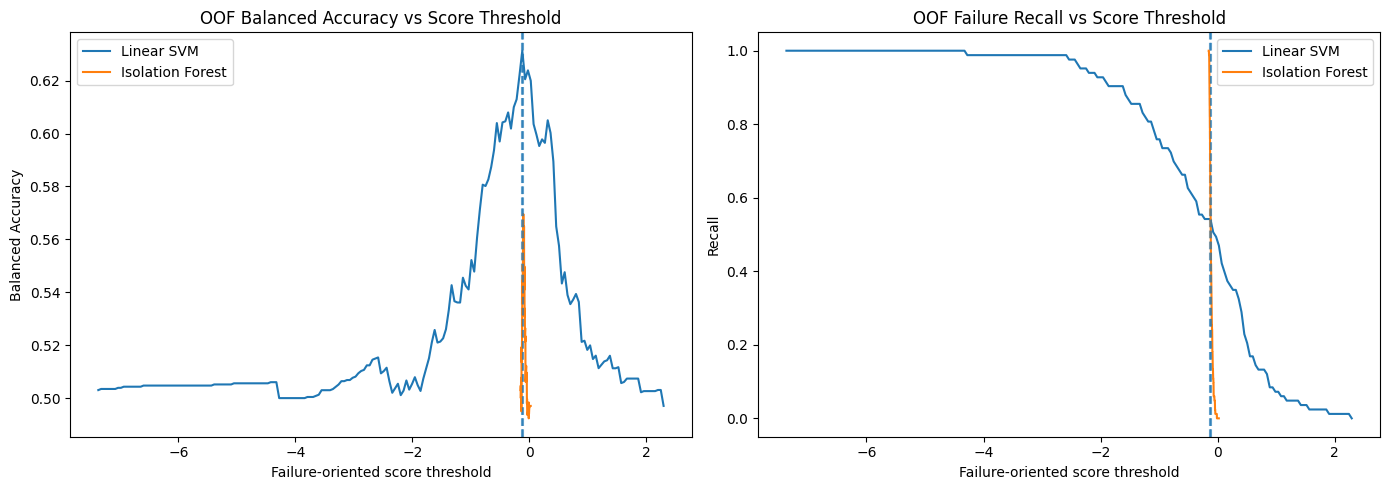

In [12]:
# 11. Visualize OOF threshold trade-offs



fig, axes = plt.subplots(1, 2, figsize=(14, 5))



for name in models:

    temp = threshold_results[threshold_results["model"] == name]



    axes[0].plot(

        temp["threshold"],

        temp["balanced_accuracy"],

        label=name,

    )



    axes[1].plot(

        temp["threshold"],

        temp["recall"],

        label=name,

    )



    axes[0].axvline(

        thresholds[name],

        linestyle="--",

        alpha=0.7,

    )

    axes[1].axvline(

        thresholds[name],

        linestyle="--",

        alpha=0.7,

    )



axes[0].set_title("OOF Balanced Accuracy vs Score Threshold")

axes[0].set_xlabel("Failure-oriented score threshold")

axes[0].set_ylabel("Balanced Accuracy")

axes[0].legend()



axes[1].set_title("OOF Failure Recall vs Score Threshold")

axes[1].set_xlabel("Failure-oriented score threshold")

axes[1].set_ylabel("Recall")

axes[1].legend()



plt.tight_layout()

plt.show()


## 12. Final evaluation on the untouched test set

Each model is now fitted on all training observations.

The test set is evaluated exactly once per model.

Thresholds were selected before this step.


In [13]:
# 12. Final evaluation on the untouched test set



final_rows = []

final_scores = {}

final_predictions = {}



for name, model in models.items():



    print("Fitting final:", name)



    model.fit(X_train, y_train)



    score = model.decision_function(X_test)

    threshold = thresholds[name]

    prediction = (score >= threshold).astype(int)



    final_scores[name] = score

    final_predictions[name] = prediction



    row = evaluate_scores(

        y_test,

        score,

        threshold=threshold,

        name=name,

    )



    final_rows.append(row)



final_results = pd.DataFrame(final_rows)



display(

    final_results[

        [

            "model",

            "threshold",

            "balanced_accuracy",

            "roc_auc",

            "pr_auc",

            "recall",

            "precision",

            "f1",

        ]

    ].sort_values(

        ["pr_auc", "balanced_accuracy"],

        ascending=False,

    ).round(4)

)


Fitting final: Linear SVM
Fitting final: Isolation Forest


,model,threshold,balanced_accuracy,roc_auc,pr_auc,recall,precision,f1
1,Isolation Forest,-0.1048,0.6833,0.6717,0.1466,0.5714,0.1667,0.2581
0,Linear SVM,-0.1228,0.6100,0.6415,0.1237,0.5238,0.1100,0.1818


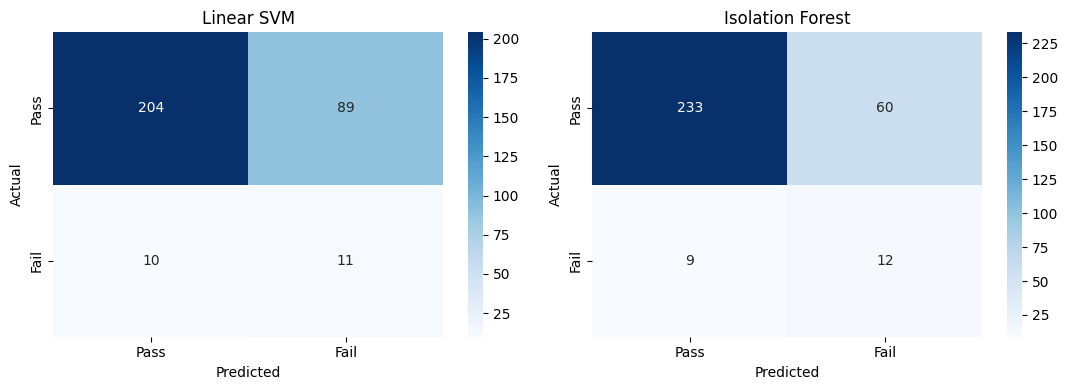

In [14]:
# 13. Confusion matrices



fig, axes = plt.subplots(1, 2, figsize=(11, 4))



for ax, name in zip(axes, models.keys()):

    cm = confusion_matrix(

        y_test,

        final_predictions[name],

    )



    sns.heatmap(

        cm,

        annot=True,

        fmt="d",

        cmap="Blues",

        xticklabels=["Pass", "Fail"],

        yticklabels=["Pass", "Fail"],

        ax=ax,

    )



    ax.set_title(name)

    ax.set_xlabel("Predicted")

    ax.set_ylabel("Actual")



plt.tight_layout()

plt.show()


In [15]:
# 14. Detailed classification reports



for name in models:

    print("=" * 70)

    print(name)

    print("=" * 70)



    print(

        classification_report(

            y_test,

            final_predictions[name],

            target_names=["Pass", "Fail"],

            zero_division=0,

        )

    )


Linear SVM
              precision    recall  f1-score   support

        Pass       0.95      0.70      0.80       293
        Fail       0.11      0.52      0.18        21

    accuracy                           0.68       314
   macro avg       0.53      0.61      0.49       314
weighted avg       0.90      0.68      0.76       314

Isolation Forest
              precision    recall  f1-score   support

        Pass       0.96      0.80      0.87       293
        Fail       0.17      0.57      0.26        21

    accuracy                           0.78       314
   macro avg       0.56      0.68      0.56       314
weighted avg       0.91      0.78      0.83       314



## 15. Model comparison



Interpret the result using:

- **Balanced Accuracy** for class-balanced classification quality

- **ROC-AUC** for ranking quality

- **PR-AUC** because failures are rare

- **Failure Recall** for missed-failure sensitivity

- **Precision** for false-alarm burden

- **F1** for recall/precision balance



For Isolation Forest, the threshold is an anomaly-score threshold. For Linear SVM, it is a decision-function threshold.



Do not select a model from raw accuracy alone.


In [16]:
# 15. Direct comparison



comparison = final_results.copy()



display(

    comparison[

        [

            "model",

            "balanced_accuracy",

            "roc_auc",

            "pr_auc",

            "recall",

            "precision",

            "f1",

        ]

    ].sort_values(

        ["pr_auc", "balanced_accuracy"],

        ascending=False,

    ).round(4)

)



best_by_pr = comparison.sort_values(

    ["pr_auc", "balanced_accuracy"],

    ascending=False,

).iloc[0]



print("Current test-set leader by PR-AUC:", best_by_pr["model"])


,model,balanced_accuracy,roc_auc,pr_auc,recall,precision,f1
1,Isolation Forest,0.6833,0.6717,0.1466,0.5714,0.1667,0.2581
0,Linear SVM,0.6100,0.6415,0.1237,0.5238,0.1100,0.1818


Current test-set leader by PR-AUC: Isolation Forest


## 16. Statistical candidate process signals

Fit the selector on the training set only for interpretation.

These are **candidate signals associated with failure**, not proof of causal root cause.


In [17]:
# Use the selector from each final fitted model.
for name, model in models.items():
    selector = model.named_steps["selector"]

    print("\n" + "="*70)
    print(name)
    print("="*70)
    print("Selected signals:", len(selector.selected_features_))

    selected_stats = selector.statistics_[
        selector.statistics_["feature"].isin(
            selector.selected_features_
        )
    ].copy()

    display(
        selected_stats[
            ["feature", "p_value", "q_value", "effect", "auc"]
        ].round(5)
    )



Linear SVM
Selected signals: 56


,feature,p_value,q_value,effect,auc
0,Sensor_104,0.00000,0.00001,0.79926,0.68147
1,Sensor_60,0.00000,0.00024,0.41883,0.65998
2,Sensor_478,0.00002,0.00256,0.11624,0.63896
3,Sensor_511,0.00002,0.00256,0.37196,0.64102
5,Sensor_34,0.00009,0.00660,0.10300,0.62832
6,Sensor_248,0.00010,0.00660,0.00000,0.62131
7,Sensor_130,0.00017,0.00962,0.11607,0.62319
10,Sensor_96,0.00039,0.01600,0.95399,0.60919
11,Sensor_317,0.00084,0.03163,0.32709,0.60951
12,Sensor_22,0.00108,0.03233,0.15709,0.60725



Isolation Forest
Selected signals: 56


,feature,p_value,q_value,effect,auc
0,Sensor_104,0.00000,0.00001,0.79926,0.68147
1,Sensor_60,0.00000,0.00024,0.41883,0.65998
2,Sensor_478,0.00002,0.00256,0.11624,0.63896
3,Sensor_511,0.00002,0.00256,0.37196,0.64102
5,Sensor_34,0.00009,0.00660,0.10300,0.62832
6,Sensor_248,0.00010,0.00660,0.00000,0.62131
7,Sensor_130,0.00017,0.00962,0.11607,0.62319
10,Sensor_96,0.00039,0.01600,0.95399,0.60919
11,Sensor_317,0.00084,0.03163,0.32709,0.60951
12,Sensor_22,0.00108,0.03233,0.15709,0.60725


In [18]:
# 17. Feature interpretation



for name, model in models.items():



    print("\n" + "="*70)

    print(name)

    print("="*70)



    selector = model.named_steps["selector"]

    imputer = model.named_steps["imputer"]

    final_model = model.named_steps["model"]



    try:

        feature_names = imputer.get_feature_names_out(

            selector.selected_features_

        )



        if hasattr(final_model, "coef_"):

            coef = np.ravel(final_model.coef_)



            coef_df = pd.DataFrame({

                "feature": feature_names,

                "coefficient": coef,

                "absolute_coefficient": np.abs(coef),

            }).sort_values(

                "absolute_coefficient",

                ascending=False,

            )



            display(coef_df.head(20))



        elif hasattr(final_model, "feature_importances_"):

            imp = pd.DataFrame({

                "feature": feature_names,

                "importance": final_model.feature_importances_,

            }).sort_values(

                "importance",

                ascending=False,

            )



            display(imp.head(20))



    except Exception as exc:

        print("Feature-name mapping skipped:", exc)



Linear SVM


,feature,coefficient,absolute_coefficient
84,missingindicator_Sensor_57,1.250669,1.250669
89,missingindicator_Sensor_41,-1.161170,1.161170
94,missingindicator_Sensor_588,-0.770973,0.770973
77,missingindicator_Sensor_271,-0.457589,0.457589
54,Sensor_122,0.455177,0.455177
93,missingindicator_Sensor_291,-0.443735,0.443735
18,Sensor_125,-0.279903,0.279903
72,missingindicator_Sensor_352,-0.245544,0.245544
96,missingindicator_Sensor_82,-0.245544,0.245544
97,missingindicator_Sensor_80,-0.245544,0.245544



Isolation Forest


# 19. Final interpretation



### Linear SVM

A large-margin linear classifier that directly tests whether the selected SECOM process signals contain a strong approximately linear decision structure. Because the SVM is linear here, its coefficients are directly interpretable after scaling.



### Isolation Forest

A normal-profile anomaly detector. It is trained only on Pass observations and ranks test samples by how isolated they are from the learned normal population. It is useful as a different problem formulation from supervised classification.



### Important caveat

The feature-selection stage is supervised (it uses pass/fail labels), so the Isolation Forest branch is **semi-supervised / label-informed**, not a pure unsupervised anomaly detector. This choice is deliberate to keep the feature-selection pipeline matched to the earlier exact setup. Test labels are never used to fit the feature selector, train the models, or choose the OOF threshold.



### Conclusion

We compare a linear large-margin classifier with a normal-only anomaly detector under the same leakage-controlled SECOM preprocessing and evaluation framework. This directly tests whether the strong Logistic Regression result is consistent with a linear SVM and whether a one-class anomaly formulation can compete with the supervised approaches tested earlier.
